# Preference models (Colab-ready)

Builds on notebooks 1–3 and (optionally) the image features from notebook 4. Fits course-aligned statistical models on the Cat Image Arena training responses and evaluates them with pair-aware splits.

**Two accepted inputs — the notebook detects which one you gave it**

| Mode | File | Where the image features come from |
|------|------|------------------------------------|
| **A** | `prepared/cleaned_training_responses.csv` (notebook 1) | separate `image_features_simple.csv` / `image_features_resnet.csv` tables from notebook 4 |
| **B** | `train_pairs.csv` (combined export) | already merged into the same table as per-row differences — `d_*` (embedding) and `h_*` (handcrafted) |

In mode B the notebook rebuilds the columns notebook 1 would have written (`chose_a`, `demo_complete`, `ordered_pair_id`, `unordered_pair_id`), so the split, the Bradley–Terry model and the §6 rankers run unchanged. The `d_*` / `h_*` values are used exactly as supplied — they were produced by the groupmate's own encoder, so they are **not** the same numbers notebook 4 would write, and no `image_features_*.csv` is needed.

**Inputs**
- `prepared/cleaned_training_responses.csv` **or** `train_pairs.csv` — required
- `prepared/side_adjusted_*_scores.csv` (notebook 2) — optional, BT vs residual scatter

**Models in this notebook**
1. **Logistic regression** on demographics + comparison type (Chapter 6)
2. **Bradley–Terry (BT)** ranking of cats via logistic regression on score differences (Chapter 7)
3. **Random forest** baseline on the same tabular features (Chapters 4–5)
4. **Image-feature ranking** $f_\theta$ on $\Delta x = x_i - x_j$ (Chapter 7 shared scorer)

**Course / report link:** This notebook supplies the *Methods*, *Results* and part of the *Interpretation* sections of the midterm report. Every model is fit only on the training fold of a pair-aware split; the held-out fold is used solely for evaluation. Preprocessing (one-hot encoding, strength estimation, feature matrices) is fit on the training fold only.

**Bottom line to expect:** demographics alone are weak; a cat-level Bradley–Terry model captures the replicable preference signal found in notebook 2; image features help especially on within-cat pairs where a single cat score cannot explain photo differences.


## 0. Setup (Colab or local)

**Purpose:** locate the training table — the notebook-1 output *or* the combined file — create the output folders, and import the libraries used by all models.

Auto-detection looks for `train_pairs.csv` (combined) first, then `cleaned_training_responses.csv`, in the working directory, `prepared/`, `/content`, and the usual Drive / artifacts paths. To pin one file explicitly, set `INPUT_PATH_OVERRIDE` in the next cell.


In [ ]:

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

warnings.filterwarnings("ignore", category=UserWarning)

# Optional: pin one file, e.g. "prepared/cleaned_training_responses.csv".
# Leave as None to auto-detect (combined file wins if both are present).
INPUT_PATH_OVERRIDE = None

# ---------------------------------------------------------------------------
# Where to look for the training data (Colab, Drive, local)
# ---------------------------------------------------------------------------
here = Path.cwd()
SEARCH_DIRS = [
    here,
    here / "prepared",
    here / "analysis",
    here / "analysis" / "prepared",
    here / "tables",
    here.parent / "prepared",
    here.parent / "analysis",
    here.parent / "analysis" / "prepared",
    here.parent / "tables",
    Path("/content"),
    Path("/content") / "prepared",
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive") / "prepared",
    Path("/home/workdir/artifacts") / "prepared",
]

# Mode A: notebook-1 output + separate image-feature tables from notebook 4
SEPARATE_NAMES = ["cleaned_training_responses.csv"]
# Mode B: combined export — responses AND image-feature deltas in one row
COMBINED_NAMES = [
    "train_pairs.csv",
    "train_pairs.csv.gz",
    "combined_train_pairs.csv",
    "train_pairs_combined.csv",
]


def _response_columns_ok(cols) -> bool:
    """True if these columns look like a Cat Image Arena response table."""
    cols = set(cols)
    has_target = {"chose_a"} <= cols or {"choice"} <= cols or {"y"} <= cols
    return {"a_image", "b_image", "comparison_type"} <= cols and has_target


def find_training_path() -> tuple[Path, str]:
    """Locate the training table; return (path, mode) with mode in {separate, combined}."""
    if INPUT_PATH_OVERRIDE is not None:
        p = Path(INPUT_PATH_OVERRIDE)
        if not p.is_absolute():
            p = Path.cwd() / p
        if not p.is_file():
            raise FileNotFoundError(f"INPUT_PATH_OVERRIDE does not exist: {p}")
        cols = pd.read_csv(p, nrows=0).columns
        has_deltas = any(c.startswith("d_") and c[2:].isdigit() for c in cols)
        return p, "combined" if has_deltas else "separate"

    for names, mode in ((COMBINED_NAMES, "combined"), (SEPARATE_NAMES, "separate")):
        for name in names:
            for d in SEARCH_DIRS:
                p = d / name
                if p.is_file():
                    return p, mode

    # Fallback: any CSV that looks like a response table
    for d in SEARCH_DIRS:
        if not d.is_dir():
            continue
        for p in sorted(d.glob("*.csv")):
            try:
                cols = pd.read_csv(p, nrows=0).columns
            except Exception:
                continue
            if _response_columns_ok(cols):
                has_deltas = any(c.startswith("d_") and c[2:].isdigit() for c in cols)
                return p, "combined" if has_deltas else "separate"

    raise FileNotFoundError(
        "Could not find a training CSV. Expected either "
        "prepared/cleaned_training_responses.csv (notebook 1) or train_pairs.csv (combined file)."
    )


TRAIN_PATH, INPUT_MODE = find_training_path()
PREPARED_DIR = TRAIN_PATH.parent
PREPARED_DIR.mkdir(parents=True, exist_ok=True)
# Alias kept for older cells/scripts that referred to CLEANED_PATH
CLEANED_PATH = TRAIN_PATH

FIG_DIR = Path.cwd() / "model-checks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path.cwd() / "model-checks"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]

RNG = np.random.default_rng(42)

print(f"Training file: {TRAIN_PATH.resolve()}")
print(f"Input mode:    {INPUT_MODE}")
print(f"Figures:       {FIG_DIR.resolve()}")
print(f"Outputs:       {OUT_DIR.resolve()}")


## 1. Load and define the modelling frame

**This section answers:** *What rows and columns enter the models, and how do we avoid leakage?*

We keep all rows for the Bradley–Terry cat model (strength estimation benefits from every between-cat comparison). Demographic models use only `demo_complete` rows.

**Comparison graph and leakage (Chapter 7):** cats, images and matchups repeat across rows, so the data form a comparison graph. A random row-wise train/test split would let the model see the same pair (or the same image) on both sides of the split — a form of leakage the midterm guidelines warn against.

How we handle leakage depends on the **generalisation claim**:

| Claim | What must stay out of training |
|-------|--------------------------------|
| Predict **unseen matchups** (new pairs) | All responses to each held-out unordered pair, including reversed A/B order |
| Predict **unseen images** | Every row that contains a held-out image |
| Predict **unseen cats** | Every row that contains a held-out cat (stricter) |

This notebook evaluates the first claim: the **validation unit is the unordered pair**. Both orientations of the same photo pair stay in the same fold, matching notebook 2’s reliability design.


In [ ]:

train_raw = pd.read_csv(TRAIN_PATH)


def _pair_ids(a_images, b_images):
    """Exactly the ids notebook 1 writes: ordered (A||B) and unordered (sorted)."""
    a = a_images.astype(str)
    b = b_images.astype(str)
    ordered = a + "||" + b
    unordered = a.where(a <= b, b) + "||" + b.where(a <= b, a)
    return ordered, unordered


def prepare_training_frame(df: pd.DataFrame):
    """Return a frame carrying the columns notebook 1 guarantees, whatever the input.

    The combined file only stores the raw export (A/B choice, demographics, and
    per-row image-feature deltas). The derived columns are rebuilt here so the
    rest of the notebook — splits, BT model, §6 rankers — runs unchanged.
    """
    df = df.copy()
    notes = []

    # 1. binary target
    if "chose_a" not in df.columns:
        if "choice" in df.columns:
            bad = sorted(set(df["choice"].dropna().unique()) - {"A", "B"})
            if bad:
                raise ValueError(f"Unexpected values in 'choice': {bad}")
            df["chose_a"] = (df["choice"] == "A").astype(int)
            notes.append("chose_a rebuilt from choice (A→1, B→0)")
        elif "y" in df.columns:
            df["chose_a"] = df["y"].astype(int)
            notes.append("chose_a rebuilt from y")
        else:
            raise ValueError("Need 'chose_a', 'choice' or 'y' to define the target.")

    if "choice" not in df.columns:
        df["choice"] = np.where(df["chose_a"] == 1, "A", "B")
        notes.append("choice recreated from chose_a")

    # 2. complete-background flag
    if "demo_complete" not in df.columns:
        have = [c for c in DEMO_COLS if c in df.columns]
        absent = sorted(set(DEMO_COLS) - set(have))
        if absent:
            raise ValueError(f"Cannot rebuild demo_complete — missing demographics: {absent}")
        df["demo_complete"] = (
            df[DEMO_COLS].notna().all(axis=1) & ~df[DEMO_COLS].eq("missing").any(axis=1)
        )
        notes.append("demo_complete rebuilt from the six demographic columns")

    # 3. pair identifiers (same construction as notebook 1)
    if "ordered_pair_id" not in df.columns or "unordered_pair_id" not in df.columns:
        ordered, unordered = _pair_ids(df["a_image"], df["b_image"])
        df["ordered_pair_id"] = ordered
        df["unordered_pair_id"] = unordered
        notes.append("ordered/unordered pair ids rebuilt from a_image/b_image")

    # 4. row id
    if "train_row_id" not in df.columns:
        df["train_row_id"] = [f"TR{i:06d}" for i in range(1, len(df) + 1)]
        notes.append("train_row_id generated from row order")

    return df, notes


train, PREP_NOTES = prepare_training_frame(train_raw)
for note in PREP_NOTES:
    print(f"[prepared] {note}")

required = [
    "train_row_id",
    "a_cat",
    "b_cat",
    "a_image",
    "b_image",
    "choice",
    "comparison_type",
    "chose_a",
    "demo_complete",
    "ordered_pair_id",
    "unordered_pair_id",
    *DEMO_COLS,
]
missing = [c for c in required if c not in train.columns]
if missing:
    raise ValueError(f"Training file is missing columns: {missing}")

train["chose_a"] = train["chose_a"].astype(int)
train["demo_complete"] = train["demo_complete"].astype(bool)

# --- image-feature blocks already merged into the table ---------------------
# d_0000 ... : embedding differences (x_a - x_b), one row per comparison
# h_<name>   : interpretable handcrafted differences, one row per comparison
ROW_D_COLS = [c for c in train.columns if c.startswith("d_") and c[2:].isdigit()]
ROW_H_COLS = [c for c in train.columns if c.startswith("h_")]
USE_ROW_DELTAS = bool(ROW_D_COLS or ROW_H_COLS)

print(f"Rows:              {len(train):,}")
print(f"Complete demo:     {int(train['demo_complete'].sum()):,}")
print(f"Unique cats:       {pd.unique(train[['a_cat','b_cat']].values.ravel()).size}")
print(f"Unique images:     {pd.unique(train[['a_image','b_image']].values.ravel()).size}")
print(f"Unordered pairs:   {train['unordered_pair_id'].nunique():,}")
print(train["comparison_type"].value_counts().to_string())
print(
    f"Per-row image deltas: {len(ROW_D_COLS)} d_* (embedding) + "
    f"{len(ROW_H_COLS)} h_* (handcrafted)"
)
print(
    "Section 6 will use those columns directly."
    if USE_ROW_DELTAS
    else "Section 6 will look for image_features_*.csv from notebook 4."
)
display(
    train[["train_row_id", "a_image", "b_image", "choice", "chose_a", "demo_complete"]].head(3)
)


### Pair-aware train / validation split

Whole **unordered pairs** are assigned to train or validation. This prevents both orientations of the same comparison from appearing in different folds and matches the split-half logic of notebook 2.

**What this split does and does not protect against**
- **Protects:** leakage of the same matchup (including A/B swap) into both folds → appropriate when the claim is “new matchups”.
- **Does not fully protect:** the same *cat* or *image* can still appear in both folds through different pairs. If the report claims generalisation to new images or new cats, use a stricter image-held-out or cat-held-out split (see Limitations).

Random row splitting is **not** used anywhere in this notebook.


In [ ]:
def pair_aware_split(df, val_frac=0.25, seed=42):
    """Assign every unordered pair to exactly one fold."""
    pairs = df["unordered_pair_id"].unique()
    rng = np.random.default_rng(seed)
    rng.shuffle(pairs)
    n_val = max(1, int(round(len(pairs) * val_frac)))
    val_pairs = set(pairs[:n_val])
    is_val = df["unordered_pair_id"].isin(val_pairs)
    return df.loc[~is_val].copy(), df.loc[is_val].copy()


train_fit, train_val = pair_aware_split(train, val_frac=0.25, seed=42)
print(f"Train fold: {len(train_fit):,} rows, {train_fit['unordered_pair_id'].nunique():,} pairs")
print(f"Valid fold: {len(train_val):,} rows, {train_val['unordered_pair_id'].nunique():,} pairs")
print(f"P(A) train: {train_fit['chose_a'].mean():.4f}   P(A) valid: {train_val['chose_a'].mean():.4f}")


Train fold: 18,622 rows, 6,037 pairs
Valid fold: 6,274 rows, 2,012 pairs
P(A) train: 0.5194   P(A) valid: 0.5177


### Shared evaluation helper

We report accuracy, ROC-AUC, log-loss and Brier score. Majority-class accuracy is the trivial baseline.


In [ ]:
def evaluate_binary(y_true, prob, name="model"):
    y_true = np.asarray(y_true).astype(int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= 0.5).astype(int)
    majority = max(y_true.mean(), 1 - y_true.mean())
    out = {
        "model": name,
        "n": len(y_true),
        "majority_acc": majority,
        "accuracy": accuracy_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob) if y_true.min() != y_true.max() else np.nan,
        "log_loss": log_loss(y_true, prob, labels=[0, 1]),
        "brier": brier_score_loss(y_true, prob),
    }
    return out


results = []


## 2. Logistic regression on demographics + comparison type (Chapter 6)

**Model:** linear score $z = \beta_0 + x^\top\beta$ mapped to $P(\text{choose A}) = \sigma(z)$.

**Features:** one-hot demographics and `comparison_type` (drop-first). Fit only on complete-background rows in the **train fold**. Evaluate on complete-background rows in the **validation fold**.

This is the same baseline introduced in notebook 3, now with a proper held-out pair-aware evaluation.


In [ ]:
feature_cols = DEMO_COLS + ["comparison_type"]

fit_demo = train_fit[train_fit["demo_complete"]].copy()
val_demo = train_val[train_val["demo_complete"]].copy()

pre = ColumnTransformer(
    [("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), feature_cols)],
    remainder="drop",
)
logit = Pipeline(
    [
        ("pre", pre),
        ("clf", LogisticRegression(max_iter=2000, solver="lbfgs")),
    ]
)
logit.fit(fit_demo[feature_cols], fit_demo["chose_a"])

prob_val_logit = logit.predict_proba(val_demo[feature_cols])[:, 1]
res_logit = evaluate_binary(val_demo["chose_a"], prob_val_logit, name="logistic_demo")
results.append(res_logit)
print("Validation (complete-background rows):")
display(pd.DataFrame([res_logit]).set_index("model").round(4))

# Coefficient table (log-odds and odds ratios)
ohe = logit.named_steps["pre"].named_transformers_["cat"]
names = ohe.get_feature_names_out(feature_cols)
coefs = logit.named_steps["clf"].coef_.ravel()
intercept = float(logit.named_steps["clf"].intercept_[0])
coef_table = (
    pd.DataFrame({"feature": names, "coef_log_odds": coefs})
    .assign(odds_ratio=lambda d: np.exp(d["coef_log_odds"]))
    .sort_values("coef_log_odds", key=lambda s: s.abs(), ascending=False)
)
print(f"Intercept (log-odds): {intercept:.4f}")
display(coef_table.round(4))


Validation (complete-background rows):


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
logistic_demo,6152,0.5174,0.5349,0.5334,0.6907,0.2488


Intercept (log-odds): 0.0234


,feature,coef_log_odds,odds_ratio
12,mbti_ie_I,-0.2458,0.7821
11,future_pet_yes,0.2448,1.2773
1,pet_history_never,0.2022,1.2241
6,pet_contact_never,-0.1601,0.8521
2,pet_history_past,0.1403,1.1506
5,pet_care_past_regular,-0.1184,0.8884
3,pet_care_never,-0.1181,0.8886
4,pet_care_occasionally,-0.1017,0.9033
10,future_pet_unsure,0.0511,1.0524
13,mbti_ie_unknown,-0.0361,0.9646


## 3. Bradley–Terry ranking of cats (Chapter 7)

**Model idea.** Give each cat a latent strength $u_c$. For a comparison of cat A vs cat B the BT model is

$$
P(\text{A preferred}) = \sigma(u_{\text{a_cat}} - u_{\text{b_cat}} + b_{\text{side}}),
$$

where $\sigma$ is the logistic function and $b_{\text{side}}$ is an optional side-A bias term. This is exactly logistic regression on the **difference of scores** (Chapter 7 links BT to the logistic model of Chapter 6).

**Scope:** we fit on **between_cats** rows only (within-cat comparisons do not identify relative cat strengths). Strengths are estimated on the train fold; validation predictions use only those strengths (cats unseen in training receive strength 0).

**Implementation:** design matrix with +1 for the left cat, −1 for the right cat, plus a side-bias column; L2-regularised logistic regression without an extra intercept (the side column plays that role).


In [ ]:
def fit_bradley_terry_cats(df, C=1.0):
    """Fit BT strengths for cats on between_cats comparisons.

    Returns
    -------
    strengths : pd.Series  index = cat id, value = estimated u_c
    side_bias : float
    model : fitted LogisticRegression (for inspection)
    cat_index : list of cat ids in column order
    """
    sub = df[df["comparison_type"] == "between_cats"].copy()
    if len(sub) < 50:
        raise ValueError("Not enough between_cats rows to fit BT.")

    cats = pd.Index(pd.unique(sub[["a_cat", "b_cat"]].values.ravel())).sort_values()
    cat_to_col = {c: i for i, c in enumerate(cats)}
    n = len(sub)
    p = len(cats)

    # Sparse-friendly dense matrix is fine for ~237 cats and ~16k rows
    X = np.zeros((n, p + 1), dtype=float)
    for i, (a, b) in enumerate(zip(sub["a_cat"].to_numpy(), sub["b_cat"].to_numpy())):
        X[i, cat_to_col[a]] = 1.0
        X[i, cat_to_col[b]] = -1.0
    X[:, -1] = 1.0  # side-A bias

    y = sub["chose_a"].to_numpy().astype(int)

    # No intercept: the side column already absorbs the global bias
    clf = LogisticRegression(
        penalty="l2",
        C=C,
        fit_intercept=False,
        max_iter=2000,
        solver="lbfgs",
    )
    clf.fit(X, y)

    strengths = pd.Series(clf.coef_.ravel()[:p], index=cats, name="strength")
    side_bias = float(clf.coef_.ravel()[-1])
    return strengths, side_bias, clf, list(cats)


def predict_bt_cats(df, strengths, side_bias):
    """Predict P(choose A) from fitted cat strengths. Unseen cats get strength 0."""
    ua = df["a_cat"].map(strengths).fillna(0.0).to_numpy()
    ub = df["b_cat"].map(strengths).fillna(0.0).to_numpy()
    z = ua - ub + side_bias
    return 1.0 / (1.0 + np.exp(-z))


bt_strengths, bt_side, bt_model, bt_cats = fit_bradley_terry_cats(train_fit, C=1.0)
print(f"Fitted BT on {len(bt_cats)} cats from the train fold")
print(f"Side-A bias (log-odds): {bt_side:.4f}")
print("Top 8 cats by strength:")
display(bt_strengths.sort_values(ascending=False).head(8).to_frame().round(4))
print("Bottom 8 cats by strength:")
display(bt_strengths.sort_values(ascending=True).head(8).to_frame().round(4))


Fitted BT on 237 cats from the train fold
Side-A bias (log-odds): 0.0939
Top 8 cats by strength:


,strength
cat_000024,1.4022
cat_000013,1.3389
cat_001013,1.3213
cat_000406,1.1659
cat_000018,1.0421
cat_000005,1.0209
cat_000015,1.0081
cat_000298,1.0035


Bottom 8 cats by strength:


,strength
cat_003674,-1.3950
cat_002229,-1.3368
cat_000145,-1.2902
cat_000486,-1.2564
cat_000911,-1.1811
cat_001122,-1.1063
cat_002956,-0.9898
cat_002717,-0.9801


In [ ]:
# Evaluate BT on between_cats rows of the validation fold
val_between = train_val[train_val["comparison_type"] == "between_cats"].copy()
prob_val_bt = predict_bt_cats(val_between, bt_strengths, bt_side)
res_bt = evaluate_binary(val_between["chose_a"], prob_val_bt, name="bradley_terry_cats")
results.append(res_bt)
print("Validation (between_cats only):")
display(pd.DataFrame([res_bt]).set_index("model").round(4))

# Also evaluate on all validation rows (within_cat gets prediction from side bias only)
prob_val_bt_all = predict_bt_cats(train_val, bt_strengths, bt_side)
res_bt_all = evaluate_binary(train_val["chose_a"], prob_val_bt_all, name="bradley_terry_cats_all_rows")
results.append(res_bt_all)
print("Validation (all rows; within_cat ≈ side bias only):")
display(pd.DataFrame([res_bt_all]).set_index("model").round(4))


Validation (between_cats only):


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
bradley_terry_cats,5545,0.517,0.5971,0.6427,0.6596,0.2339


Validation (all rows; within_cat ≈ side bias only):


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
bradley_terry_cats_all_rows,6274,0.5177,0.5885,0.6309,0.6634,0.2357


### Compare BT strengths with notebook-2 empirical residuals

If notebook 2 exported `side_adjusted_cat_scores_between.csv`, we correlate the BT strengths with those residual win rates. High correlation means BT is recovering the same ranking signal under a proper likelihood.


In [ ]:

EMP_FILE = "side_adjusted_cat_scores_between.csv"
emp_path = next(
    (d / EMP_FILE for d in [PREPARED_DIR, Path.cwd(), Path.cwd() / "prepared", Path("/content")]
     if (d / EMP_FILE).is_file()),
    None,
)

if emp_path is not None:
    emp = pd.read_csv(emp_path).set_index("cat")
    joined = bt_strengths.to_frame().join(emp[["resid", "n"]], how="inner")
    # Restrict to cats with a reasonable number of appearances in the empirical table
    joined = joined[joined["n"] >= 8]
    corr = float(joined["strength"].corr(joined["resid"]))
    print(f"Correlation BT strength vs notebook-2 residual win rate (n≥8): {corr:.3f}")
    print(f"Cats in common: {len(joined)}")

    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    ax.scatter(joined["resid"], joined["strength"], s=18, alpha=0.55, color="C0")
    ax.set_xlabel("Notebook-2 residual win rate")
    ax.set_ylabel("BT strength (train fold)")
    ax.set_title(f"BT vs empirical residuals  (r = {corr:.2f})")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(0, color="0.5", lw=0.8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "bt_vs_empirical_residuals.png", bbox_inches="tight")
    plt.show()
else:
    print(
        f"{EMP_FILE} not found. Re-run notebook 2 (with the export cell) to enable this comparison."
    )


### What a single-score BT model cannot capture (Chapter 7)

A Bradley–Terry model with **one latent strength per cat** implies stochastic transitivity in expectation:

$$
p_{ij} > \tfrac12,\quad p_{jk} > \tfrac12 \quad\Longrightarrow\quad p_{ik} > \tfrac12.
$$

Consequently a single fixed score per object **cannot** represent systematic population preferences that form cycles (the Rock–Paper–Scissors pattern on the lecture slide). A few practical implications for this project:

- An *observed* cycle of three match outcomes is still possible under BT because outcomes are random; the limitation is about *systematic* non-transitive preferences.
- Changing context or heterogeneous judges (different demographic groups, within-cat vs between-cat tasks) can produce patterns that one common score misses.
- Standard BT has no tie outcome; ties need an extension or an explicit data-handling rule (not an issue here — every row has a hard A/B choice).

**Link to our EDA:** notebook 2 found that within-cat image reliability is much weaker than cat-level reliability, and notebook 3 found only small demographic effects. That pattern is consistent with a useful cat-level ranking **plus** residual photo- or judge-specific structure that a single score does not absorb.

**Course next step:** instead of a free score per known item, learn a shared ranking function $f_\theta(q, i)$ of a query/context $q$ and item features $i$ (Chapter 7, “Learning a Ranking Function for New Items”). For a preferred pair $i \succ j$,

$$
\Delta f = f_\theta(q,i) - f_\theta(q,j),
$$

and train with logistic loss $\ell_{\log}(\Delta f) = \log(1+e^{-\Delta f})$ or hinge loss $\ell_{\mathrm{hinge}}(\Delta f) = \max(0, 1-\Delta f)$. A linear scorer $f_\theta(q,i) = \theta^\top x_{q,i}$ is trained on feature differences $x_{q,i}-x_{q,j}$ and can generalise to new images when features are available.


## 4. Random forest baseline (Chapters 4–5)

Same feature set as the logistic model (demographics + comparison type). Trees can capture interactions that a linear score misses; the ensemble reduces variance (Chapter 5). We keep the forest modest so it stays interpretable and fast.


Validation (complete-background rows):


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
random_forest_demo,6152,0.5174,0.5294,0.5367,0.6884,0.2477


,feature,importance
18,mbti_ie_I,0.1159
14,future_pet_no,0.1023
16,future_pet_yes,0.0911
17,mbti_ie_E,0.0833
2,pet_history_current,0.0676
0,gender_man,0.0577
13,pet_contact_sometimes,0.0548
15,future_pet_unsure,0.0473
1,gender_woman,0.0460
7,pet_care_occasionally,0.0411


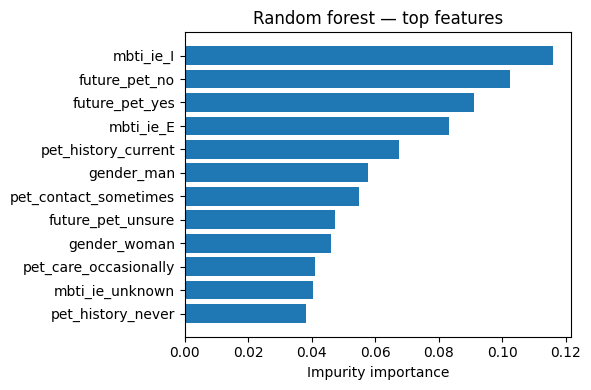

In [ ]:
rf_pre = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols)],
    remainder="drop",
)
rf = Pipeline(
    [
        ("pre", rf_pre),
        (
            "clf",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=6,
                min_samples_leaf=50,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)
rf.fit(fit_demo[feature_cols], fit_demo["chose_a"])

prob_val_rf = rf.predict_proba(val_demo[feature_cols])[:, 1]
res_rf = evaluate_binary(val_demo["chose_a"], prob_val_rf, name="random_forest_demo")
results.append(res_rf)
print("Validation (complete-background rows):")
display(pd.DataFrame([res_rf]).set_index("model").round(4))

# Feature importances
rf_ohe = rf.named_steps["pre"].named_transformers_["cat"]
rf_names = rf_ohe.get_feature_names_out(feature_cols)
importances = rf.named_steps["clf"].feature_importances_
imp_table = (
    pd.DataFrame({"feature": rf_names, "importance": importances})
    .sort_values("importance", ascending=False)
)
display(imp_table.head(15).round(4))

fig, ax = plt.subplots(figsize=(6, 4))
top = imp_table.head(12).iloc[::-1]
ax.barh(top["feature"], top["importance"], color="C0")
ax.set_xlabel("Impurity importance")
ax.set_title("Random forest — top features")
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_feature_importance.png", bbox_inches="tight")
plt.show()


## 5. Optional hybrid: BT score + demographics

Add the BT-predicted log-odds (from cat strengths) as a single numeric feature alongside demographics, then re-fit logistic regression. This tests whether demographics add anything **after** the ranking signal is accounted for.


In [ ]:
def bt_logodds(df, strengths, side_bias):
    ua = df["a_cat"].map(strengths).fillna(0.0).to_numpy()
    ub = df["b_cat"].map(strengths).fillna(0.0).to_numpy()
    return ua - ub + side_bias


fit_h = fit_demo.copy()
val_h = val_demo.copy()
fit_h["bt_logit"] = bt_logodds(fit_h, bt_strengths, bt_side)
val_h["bt_logit"] = bt_logodds(val_h, bt_strengths, bt_side)

hybrid_cols = feature_cols + ["bt_logit"]
hybrid_pre = ColumnTransformer(
    [
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), feature_cols),
        ("num", "passthrough", ["bt_logit"]),
    ]
)
hybrid = Pipeline(
    [
        ("pre", hybrid_pre),
        ("clf", LogisticRegression(max_iter=2000, solver="lbfgs")),
    ]
)
hybrid.fit(fit_h[hybrid_cols], fit_h["chose_a"])

prob_val_hybrid = hybrid.predict_proba(val_h[hybrid_cols])[:, 1]
res_hybrid = evaluate_binary(val_h["chose_a"], prob_val_hybrid, name="logistic_demo_plus_bt")
results.append(res_hybrid)
print("Validation (complete-background rows):")
display(pd.DataFrame([res_hybrid]).set_index("model").round(4))


Validation (complete-background rows):


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
logistic_demo_plus_bt,6152,0.5174,0.5987,0.6387,0.6614,0.2346


## 6. Image-feature ranking model (Chapter 7 shared scorer)

**Model:** for each preference row build the feature difference

$$
\Delta x = x_{\text{a_image}} - x_{\text{b_image}},
\qquad
P(\text{choose A}) = \sigma(\theta^\top \Delta x + b_{\mathrm{side}}).
$$

This is logistic regression on score differences — the same link as Bradley–Terry — but with a **shared** linear scorer on image features, so one set of weights can score any photo and capture within-cat photo differences that a single cat strength cannot.

**Two ways to supply $\Delta x$**

| Input mode | $\Delta x$ comes from | Feature blocks |
|---|---|---|
| **A** — notebook-1 output + notebook 4 | `image_features_simple.csv` / `image_features_resnet.csv`, joined on `a_image` / `b_image` | 11 handcrafted, 512-d ResNet18 |
| **B** — combined `train_pairs.csv` | columns already present in the table, no join needed | `h_*` handcrafted, `d_*` embedding |

Everything below goes through one helper, so both modes share the same fitting, regularisation and evaluation code — only the source of $\Delta x$ changes.

In mode B the ranker never reads `a_image` / `b_image`: it works from the precomputed differences, which is why no image folder or notebook-4 run is required. The trade-off is that a *new* photo needs the same encoder before it can be scored (see §8).


In [ ]:

def load_image_feature_table(name: str):
    """Load a per-image feature CSV; return None if missing."""
    for d in [
        PREPARED_DIR,
        Path.cwd(),
        Path.cwd() / "prepared",
        Path("/content"),
        Path("/content") / "prepared",
        Path("/content/drive/MyDrive"),
    ]:
        p = d / name
        if p.is_file():
            df = pd.read_csv(p)
            print(f"Loaded {p}  shape={df.shape}")
            return df
    print(f"Not found: {name}")
    return None


if USE_ROW_DELTAS:
    simple_feat = resnet_feat = None
    print(
        "Combined file detected → per-row delta columns are used; "
        "image_features_*.csv are not required."
    )
else:
    simple_feat = load_image_feature_table("image_features_simple.csv")
    resnet_feat = load_image_feature_table("image_features_resnet.csv")

HAS_SIMPLE = simple_feat is not None and "image" in simple_feat.columns
HAS_RESNET = resnet_feat is not None and "image" in resnet_feat.columns
print(f"USE_ROW_DELTAS={USE_ROW_DELTAS}  HAS_SIMPLE={HAS_SIMPLE}  HAS_RESNET={HAS_RESNET}")


In [ ]:

def feature_columns(df, prefix_filter=None, exclude=("image", "cat", "ok")):
    cols = [c for c in df.columns if c not in exclude]
    if prefix_filter is not None:
        cols = [c for c in cols if c.startswith(prefix_filter)]
    return cols


def numeric_cols(df, cols):
    return [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]


def build_delta_from_image_table(df, feat_df, feat_cols):
    """Δx for each row, joining per-image features on a_image / b_image."""
    fmap = feat_df.drop_duplicates("image").set_index("image")[feat_cols]
    a = fmap.reindex(df["a_image"]).to_numpy(dtype=float)
    b = fmap.reindex(df["b_image"]).to_numpy(dtype=float)
    ok = np.isfinite(a).all(axis=1) & np.isfinite(b).all(axis=1)
    return a - b, ok


def build_delta_from_row_columns(df, feat_cols):
    """Δx for each row, read straight from the combined file (already x_a - x_b)."""
    vals = df[feat_cols].to_numpy(dtype=float)
    ok = np.isfinite(vals).all(axis=1)
    return vals, ok


def image_table_delta_fn(feat_df):
    """Wrap a per-image feature table into a delta_fn(df, cols) callable."""
    def _fn(df, feat_cols):
        return build_delta_from_image_table(df, feat_df, feat_cols)
    return _fn


def fit_feature_ranker(train_df, val_df, delta_fn, feat_cols, name, C=1.0):
    """Fit σ(θᵀΔx + b_side) on the train fold, evaluate on the validation fold.

    delta_fn(df, cols) -> (delta matrix, mask of rows with a complete feature vector)
    """
    d_tr, ok_tr = delta_fn(train_df, feat_cols)
    d_va, ok_va = delta_fn(val_df, feat_cols)
    y_tr = train_df["chose_a"].to_numpy().astype(int)[ok_tr]
    y_va = val_df["chose_a"].to_numpy().astype(int)[ok_va]

    if len(y_tr) < 50 or len(y_va) < 20:
        print(f"[{name}] too few complete rows — skip")
        return None

    # side-bias column
    X_tr = np.column_stack([d_tr[ok_tr], np.ones(int(ok_tr.sum()))])
    X_va = np.column_stack([d_va[ok_va], np.ones(int(ok_va.sum()))])

    clf = LogisticRegression(
        penalty="l2",
        C=C,
        fit_intercept=False,
        max_iter=2000,
        solver="lbfgs",
    )
    clf.fit(X_tr, y_tr)
    prob = clf.predict_proba(X_va)[:, 1]
    res = evaluate_binary(y_va, prob, name=name)

    # also break down by comparison_type on validation
    val_ok = val_df.loc[ok_va].copy()
    val_ok = val_ok.assign(_prob=prob)
    breakdown = {}
    for ctype, sub in val_ok.groupby("comparison_type"):
        if len(sub) < 10:
            continue
        breakdown[ctype] = evaluate_binary(sub["chose_a"], sub["_prob"], name=f"{name}|{ctype}")

    return res, breakdown, clf, (delta_fn, feat_cols)


# Fitted delta-based rankers, reused by the prediction section (§8)
delta_models = {}


### 6a. Interpretable handcrafted features

Brightness, contrast, colour, saturation, edge energy — easy to discuss in the report.

From the combined file these arrive as `h_*` columns, which are already $x_a - x_b$ (verified: swapping A/B flips their sign). In mode A they come from `image_features_simple.csv` instead.


In [ ]:

if USE_ROW_DELTAS and ROW_H_COLS:
    hand_cols = numeric_cols(train, ROW_H_COLS)
    hand_delta_fn = build_delta_from_row_columns
    hand_name, hand_C = "rank_handcrafted_delta", 1.0
    print(f"Handcrafted delta columns ({len(hand_cols)}):", hand_cols)
elif HAS_SIMPLE:
    hand_cols = numeric_cols(simple_feat, feature_columns(simple_feat))
    hand_delta_fn = image_table_delta_fn(simple_feat)
    hand_name, hand_C = "rank_simple_images", 1.0
    print("Simple feature columns:", hand_cols)
else:
    hand_cols = None
    print("No handcrafted features available (no h_* columns and no image_features_simple.csv).")

if hand_cols:
    out = fit_feature_ranker(
        train_fit, train_val, hand_delta_fn, hand_cols,
        name=hand_name, C=hand_C,
    )
    if out is not None:
        res_s, br_s, clf_s, spec_s = out
        results.append(res_s)
        delta_models[hand_name] = {
            "clf": clf_s, "spec": spec_s, "C": hand_C, "auc": res_s["roc_auc"],
        }
        display(pd.DataFrame([res_s]).set_index("model").round(4))
        if br_s:
            display(pd.DataFrame(br_s.values()).set_index("model").round(4))
        coef_s = pd.Series(clf_s.coef_.ravel()[:-1], index=hand_cols)
        coef_s = coef_s.reindex(coef_s.abs().sort_values(ascending=False).index)
        print("Coefficients (log-odds per unit Δfeature; side bias excluded):")
        display(coef_s.round(4).to_frame("coef"))
        print(f"Side-A bias: {clf_s.coef_.ravel()[-1]:.4f}")


### 6b. Embedding-delta ranker

The high-capacity block: 512-d L2-normalised ResNet18 embeddings from notebook 4, or the `d_*` embedding differences that came with the combined file.

Coefficients are not individually interpretable, so we only report metrics. Use lighter regularisation (`C=0.1`) because of the higher dimension.


In [ ]:

if USE_ROW_DELTAS and ROW_D_COLS:
    emb_cols = numeric_cols(train, ROW_D_COLS)
    emb_delta_fn = build_delta_from_row_columns
    emb_name, emb_C = "rank_embedding_delta", 0.1
elif HAS_RESNET:
    emb_cols = feature_columns(resnet_feat, prefix_filter="r")
    if not emb_cols:
        emb_cols = numeric_cols(resnet_feat, feature_columns(resnet_feat))
    emb_delta_fn = image_table_delta_fn(resnet_feat)
    emb_name, emb_C = "rank_resnet_images", 0.1
else:
    emb_cols = None
    print("Skipping embedding ranker — no d_* columns and no image_features_resnet.csv.")

if emb_cols:
    print(f"Embedding feature dim: {len(emb_cols)}")
    out = fit_feature_ranker(
        train_fit, train_val, emb_delta_fn, emb_cols,
        name=emb_name, C=emb_C,
    )
    if out is not None:
        res_r, br_r, clf_r, spec_r = out
        results.append(res_r)
        delta_models[emb_name] = {
            "clf": clf_r, "spec": spec_r, "C": emb_C, "auc": res_r["roc_auc"],
        }
        display(pd.DataFrame([res_r]).set_index("model").round(4))
        if br_r:
            display(pd.DataFrame(br_r.values()).set_index("model").round(4))
        print(f"Side-A bias: {clf_r.coef_.ravel()[-1]:.4f}")
        print(f"(Embedding coefficients omitted — {len(emb_cols)} dimensions.)")


### 6c. Optional: handcrafted image features + demographics

Concatenate $\Delta x_{\mathrm{handcrafted}}$ with one-hot demographics on complete-background rows. Tests whether demographics still help after visual differences are accounted for.


In [ ]:

if USE_ROW_DELTAS and ROW_H_COLS:
    hand_cols = numeric_cols(train, ROW_H_COLS)
    hand_delta_fn = build_delta_from_row_columns
elif HAS_SIMPLE:
    hand_cols = numeric_cols(simple_feat, feature_columns(simple_feat))
    hand_delta_fn = image_table_delta_fn(simple_feat)
else:
    hand_cols = None

if hand_cols:
    fit_c = train_fit[train_fit["demo_complete"]].copy()
    val_c = train_val[train_val["demo_complete"]].copy()

    d_tr, ok_tr = hand_delta_fn(fit_c, hand_cols)
    d_va, ok_va = hand_delta_fn(val_c, hand_cols)
    fit_c, val_c = fit_c.loc[ok_tr].copy(), val_c.loc[ok_va].copy()
    d_tr, d_va = d_tr[ok_tr], d_va[ok_va]

    # one-hot demographics on the filtered frames
    demo_cols = DEMO_COLS + ["comparison_type"]
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), demo_cols)],
        remainder="drop",
    )
    Xdemo_tr = pre.fit_transform(fit_c[demo_cols])
    Xdemo_va = pre.transform(val_c[demo_cols])
    if hasattr(Xdemo_tr, "toarray"):
        Xdemo_tr = Xdemo_tr.toarray()
        Xdemo_va = Xdemo_va.toarray()

    X_tr = np.column_stack([d_tr, Xdemo_tr, np.ones(len(d_tr))])
    X_va = np.column_stack([d_va, Xdemo_va, np.ones(len(d_va))])
    y_tr = fit_c["chose_a"].to_numpy().astype(int)
    y_va = val_c["chose_a"].to_numpy().astype(int)

    clf_h = LogisticRegression(penalty="l2", C=1.0, fit_intercept=False, max_iter=2000, solver="lbfgs")
    clf_h.fit(X_tr, y_tr)
    prob_h = clf_h.predict_proba(X_va)[:, 1]
    res_h = evaluate_binary(y_va, prob_h, name="rank_handcrafted_plus_demo")
    results.append(res_h)
    display(pd.DataFrame([res_h]).set_index("model").round(4))
else:
    print("Skipping image+demo hybrid — no handcrafted features available.")


## 7. Results summary and interpretation

All metrics below are on the **held-out pair fold**. Compare models only within the same row set (complete-background vs between_cats).

Model names depend on the input mode: `rank_handcrafted_delta` / `rank_embedding_delta` in mode B, `rank_simple_images` / `rank_resnet_images` in mode A.


In [ ]:
summary = pd.DataFrame(results).set_index("model")
display(summary.round(4))

summary.to_csv(OUT_DIR / "model_comparison_val.csv")
bt_strengths.sort_values(ascending=False).to_csv(OUT_DIR / "bt_cat_strengths_train.csv", header=True)
print(f"Wrote {OUT_DIR / 'model_comparison_val.csv'}")
print(f"Wrote {OUT_DIR / 'bt_cat_strengths_train.csv'}")


,n,majority_acc,accuracy,roc_auc,log_loss,brier
model,,,,,,
logistic_demo,6152,0.5174,0.5349,0.5334,0.6907,0.2488
bradley_terry_cats,5545,0.5170,0.5971,0.6427,0.6596,0.2339
bradley_terry_cats_all_rows,6274,0.5177,0.5885,0.6309,0.6634,0.2357
random_forest_demo,6152,0.5174,0.5294,0.5367,0.6884,0.2477
logistic_demo_plus_bt,6152,0.5174,0.5987,0.6387,0.6614,0.2346
rank_simple_images,6274,0.5177,0.5269,0.5267,0.6919,0.2494
rank_resnet_images,6274,0.5177,0.5708,0.6008,0.6760,0.2416
rank_simple_plus_demo,6152,0.5174,0.5413,0.5468,0.6897,0.2483


Wrote /content/model-checks/model_comparison_val.csv
Wrote /content/model-checks/bt_cat_strengths_train.csv


### Interpretation (for the report)

| Finding | Course link | Report use |
|---------|-------------|------------|
| Logistic demographics ≈ majority class | Ch 6: linear score on weak features | Demographics alone are not a strong preference model |
| BT cat model lifts AUC / lowers log-loss on between_cats | Ch 7: logistic on score differences | Ranking signal is real and recoverable |
| BT strengths correlate with notebook-2 residuals | Reliability (nb 2) + BT likelihood | Empirical win rates and BT recover the same ordering |
| Forest on demographics similar to logistic | Ch 4–5: trees + bagging | Interactions among demographics do not unlock large gains |
| Hybrid (BT + demo) close to pure BT | Nested model comparison | After ranking is accounted for, demographics add little |
| Image-feature ranker (handcrafted / embedding) | Ch 7 shared scorer $f_\theta$ on $\Delta x$ | Captures photo-level differences; helps within_cat pairs |
| Comparison graph / repeated cats & images | Ch 7 comparison graph | Must use pair- or image-aware splits; random row splits leak |
| Single-score BT cannot represent systematic cycles | Ch 7 “What a single-score BT cannot capture” | Image features / $f_\theta$ address part of this limitation |

**Limitations to state in the report**
- **Leakage / generalisation claim:** the pair-aware split protects against orientation leakage (unseen *matchups*) but still allows the same *cat* or *image* to appear in both folds through different pairs. If the report claims generalisation to new images or new cats, use a stricter image-held-out or cat-held-out split and state that claim explicitly.
- **Combined-file caveat (mode B):** `d_*` / `h_*` differences were precomputed by another pipeline; they do not match notebook 4's ResNet18 table bit-for-bit, so the two feature sets are not interchangeable. A brand-new photo can only be scored after re-running that encoder.
- **Single-score BT:** one strength per cat cannot capture systematic cyclic preferences or strong context/judge heterogeneity (Chapter 7). Image-feature rankers mitigate the *photo-level* part of this gap but still use a linear score difference (no explicit cycle model).
- BT was fit only on between-cats comparisons; image-feature models use all pairs and are the natural tool for within-cat preference.
- No respondent id → multiple rows may come from the same person; dependence is not modelled.
- Regularisation (`C`) was not fully cross-validated; a path or nested CV would be a natural extension (Chapter 3).
- Embedding features are not human-interpretable; report handcrafted-feature coefficients for interpretation and embedding metrics for predictive strength.

**Suggested next steps**
1. **Stricter validation:** image-held-out or cat-held-out splits, matched to the intended generalisation claim.
2. Combine embedding $\Delta x$ with cat-level BT scores or a small non-linear head (Chapter 8).
3. Calibrated probabilities for the official test set (`prob_a`) if the group submits predictions.


## 8. Scoring pairs and exporting predictions

`predict_proba_pairs` applies a fitted ranker to any table that carries the same $\Delta x$ columns — the whole file, the held-out fold, or a new batch from the same extraction pipeline. It returns $P(\text{choose A})$ per row.

Two files are written:

| File | Fit on | Use |
|------|--------|-----|
| `predictions_val.csv` | train fold only | honest held-out predictions, safe to report |
| `predictions_all_rows_refit.csv` | every row | a complete `prob_a` column for a submission; **in-sample**, not for reporting accuracy |

**Scoring a genuinely new photo pair:** the combined file only stores precomputed differences, so first produce the same `d_*` / `h_*` columns for the new pairs with the groupmate's encoder (or notebook 4 for mode A), then pass them here.


In [ ]:

def predict_proba_pairs(clf, df, spec):
    """Return P(choose A) for every row; NaN where the feature vector is incomplete."""
    delta_fn, feat_cols = spec
    delta, ok = delta_fn(df, feat_cols)
    prob = np.full(len(df), np.nan)
    if ok.any():
        X = np.column_stack([delta[ok], np.ones(int(ok.sum()))])
        prob[ok] = clf.predict_proba(X)[:, 1]
    return prob


if delta_models:
    best_name = max(
        delta_models,
        key=lambda k: -1.0 if pd.isna(delta_models[k]["auc"]) else delta_models[k]["auc"],
    )
    best = delta_models[best_name]
    auc_txt = "n/a" if pd.isna(best["auc"]) else f"{best['auc']:.4f}"
    print(f"Best delta-based ranker on the validation fold: {best_name} (AUC={auc_txt})")

    # (a) honest held-out predictions from the fold-fitted model
    val_out = train_val[
        ["train_row_id", "a_image", "b_image", "comparison_type", "chose_a"]
    ].copy()
    val_out["prob_a"] = predict_proba_pairs(best["clf"], train_val, best["spec"])
    val_out.to_csv(OUT_DIR / "predictions_val.csv", index=False)
    print(f"Wrote {OUT_DIR / 'predictions_val.csv'}  ({len(val_out):,} rows)")

    # (b) refit on every row, then score every row (submission-style export)
    clf_full = LogisticRegression(
        penalty="l2", C=best["C"], fit_intercept=False, max_iter=2000, solver="lbfgs"
    )
    d_full, ok_full = best["spec"][0](train, best["spec"][1])
    clf_full.fit(
        np.column_stack([d_full[ok_full], np.ones(int(ok_full.sum()))]),
        train["chose_a"].to_numpy()[ok_full],
    )
    all_out = train[
        ["train_row_id", "a_image", "b_image", "comparison_type", "chose_a"]
    ].copy()
    all_out["prob_a"] = predict_proba_pairs(clf_full, train, best["spec"])
    all_out.to_csv(OUT_DIR / "predictions_all_rows_refit.csv", index=False)
    print(f"Wrote {OUT_DIR / 'predictions_all_rows_refit.csv'}  ({len(all_out):,} rows)")
    print("  (b) is refit on every row — in-sample, so do not quote its accuracy as a result.")
    display(all_out.head(3).round(4))
else:
    print("No delta-based ranker was fitted, so there is nothing to export.")


## 9. Reproducibility checklist

- [ ] A training table was found: `cleaned_training_responses.csv` (notebook 1) **or** the combined `train_pairs.csv`
- [ ] Notebook 2 has written the side-adjusted score CSVs (optional but useful for the BT scatter)
- [ ] Mode A: notebook 4 has written `image_features_simple.csv` / `image_features_resnet.csv`; mode B uses the `d_*` / `h_*` columns instead
- [ ] This notebook finished without error and wrote `model-checks/model_comparison_val.csv`
- [ ] `model-checks/predictions_val.csv` and `model-checks/predictions_all_rows_refit.csv` were written
- [ ] Figures under `model-checks/figures/` are available for the report slides
- [ ] Any claim about generalisation is paired with a description of the pair-aware (or stricter image/cat-held-out) split
- [ ] The report states that a single-score BT cannot represent systematic cycles and points to image features / $f_\theta$ where relevant
